In [2]:
import pandas as pd
df = pd.read_csv('tips.csv')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
import sklearn
from sklearn.model_selection import train_test_split
X = df[["total_bill"]]
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print('X_train:', X_train, 'X_test:', X_test, 'y_train:', y_train, 'y_test:', y_test)

X_train:      total_bill
234       15.53
227       20.45
180       34.65
5         25.29
56        38.01
..          ...
106       20.49
14        14.83
92         5.75
179       34.63
102       44.30

[170 rows x 1 columns] X_test:      total_bill
24        19.82
6          8.77
153       24.55
211       25.89
198       13.00
..          ...
165       24.52
154       19.77
216       28.15
79        17.29
29        19.65

[74 rows x 1 columns] y_train: 234    3.00
227    3.00
180    3.68
5      4.71
56     3.00
       ... 
106    4.06
14     3.02
92     1.00
179    3.55
102    2.50
Name: tip, Length: 170, dtype: float64 y_test: 24     3.18
6      2.00
153    2.00
211    5.16
198    2.00
       ... 
165    3.48
154    2.00
216    3.00
79     2.71
29     3.00
Name: tip, Length: 74, dtype: float64


In [4]:
len(X_train)

170

Since we are using the data for training and testing, we set aside 30% of the data for testing and 70% for training. We do this so we can train and learn the parameters of the model.

In [5]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.4291782688312412


In [6]:
print(model.coef_, model.intercept_)

[0.10889371] 0.8769576391532707


each extra dollar of bill adds about 0.10889371 of tip

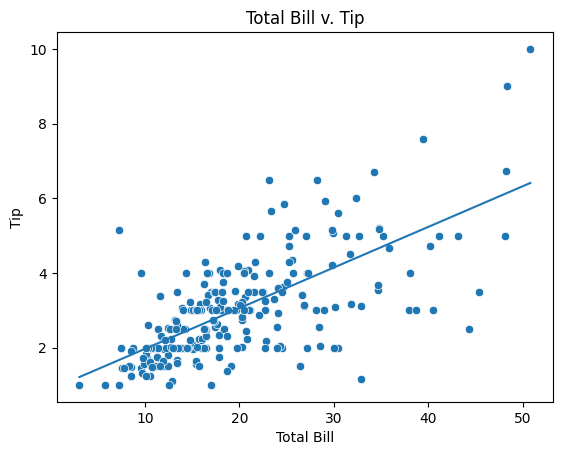

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data = df, x='total_bill', y = 'tip')
sns.lineplot(data = df, x='total_bill', y = model.predict(X))
plt.title('Total Bill v. Tip')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.show()

In [8]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [9]:
from sklearn.model_selection import train_test_split
X = df[["petal width (cm)"]]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print('X_train:', X_train, 'X_test:', X_test, 'y_train:', y_train, 'y_test:', y_test)

X_train:      petal width (cm)
81                1.0
133               1.5
137               1.8
75                1.4
109               2.5
..                ...
71                1.3
106               1.7
14                0.2
92                1.2
102               2.1

[105 rows x 1 columns] X_test:      petal width (cm)
73                1.2
18                0.3
118               2.3
78                1.5
76                1.4
31                0.4
64                1.3
141               2.3
68                1.5
82                1.2
110               2.0
12                0.1
36                0.2
9                 0.1
19                0.3
56                1.6
104               2.2
69                1.1
55                1.3
132               2.2
29                0.2
127               1.8
26                0.4
128               2.1
131               2.0
145               2.3
108               1.8
143               2.3
45                0.3
30                0.2
22           

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(max_depth=3)

In [11]:
knn.fit(X_train, y_train)
print(knn.score(X_test, y_test))

0.9555555555555556


In [12]:
tree.fit(X_train, y_train)
print(tree.score(X_test, y_test))

1.0


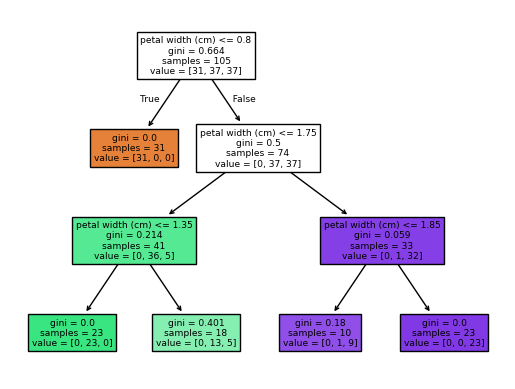

In [13]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plot_tree(tree, feature_names=X_train.columns, filled=True)
plt.show()

Root split explained: is the petal width less than or equal to 0.8 centimeters?

In [14]:
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
print(tree.score(X_train, y_train))

0.9428571428571428


In [15]:
tree.fit(X_test, y_test)
print(tree.score(X_test, y_test))

1.0


The test score is 1.0 while the training score is about 0.94, resulting in a difference of 0.6.

In [16]:
df.loc[len(df)] = [4.5, 3.2, 1.4, 0.2, 0]
df.tail()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0
149,5.9,3.0,5.1,1.8,2.0
150,4.5,3.2,1.4,0.2,0.0


In [27]:
prediction = df.loc[[150], ['petal width (cm)']]
print("Making a prediction for the petal width:")
print(prediction)
print("The prediction is:")
print(tree.predict(prediction))

Making a prediction for the petal width:
     petal width (cm)
150               0.2
The prediction is:
[0]


According to the tree model, the new value is closest to the 0 value. This means that based on the petal width given, the flower is a part of whatever species is associated with [0]. For this data set, I would ship the treen score because it has 100% accuracy while the knn score has 95% accuracy. In the case the data quality is not up to standard, I can see the tree model failing to provide accurate information. Innacurate starting data will lead to inaccuarate predictions. One bias risk I can think of is an over-representation of one race if the data was about humans instead of flowers.